In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv("df.xls",header=None,names=['ID','Brand','Sentiment','Phrase'])

In [3]:
df.head()

,ID,Brand,Sentiment,Phrase
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [4]:
df=df[['Brand','Sentiment','Phrase']]
df.head()

,Brand,Sentiment,Phrase
0,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,Borderlands,Positive,I am coming to the borders and I will kill you...
2,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,Borderlands,Positive,im coming on borderlands and i will murder you...
4,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [5]:
df.isnull().sum()

Brand          0
Sentiment      0
Phrase       686
dtype: int64

In [6]:
df=df.dropna()

In [7]:
df.isnull().sum()

Brand        0
Sentiment    0
Phrase       0
dtype: int64

In [8]:
df.head()

,Brand,Sentiment,Phrase
0,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,Borderlands,Positive,I am coming to the borders and I will kill you...
2,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,Borderlands,Positive,im coming on borderlands and i will murder you...
4,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [9]:
df.Sentiment.value_counts()

Sentiment
Negative      22358
Positive      20655
Neutral       18108
Irrelevant    12875
Name: count, dtype: int64

In [10]:
from sklearn.preprocessing import LabelEncoder

In [11]:
le=LabelEncoder()
df['Sentiment']=le.fit_transform(df['Sentiment'])

In [12]:
le.classes_

array(['Irrelevant', 'Negative', 'Neutral', 'Positive'], dtype=object)

In [13]:
df.head()

,Brand,Sentiment,Phrase
0,Borderlands,3,im getting on borderlands and i will murder yo...
1,Borderlands,3,I am coming to the borders and I will kill you...
2,Borderlands,3,im getting on borderlands and i will kill you ...
3,Borderlands,3,im coming on borderlands and i will murder you...
4,Borderlands,3,im getting on borderlands 2 and i will murder ...


In [14]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [15]:
#Intializing tokenizer for word index
tokenizer=Tokenizer(num_words=15000,oov_token="<OOV")
tokenizer.fit_on_texts(df['Phrase'])
word_index = tokenizer.word_index
word_index

{'<OOV': 1,
 'the': 2,
 'i': 3,
 'to': 4,
 'and': 5,
 'a': 6,
 'of': 7,
 'is': 8,
 'in': 9,
 'for': 10,
 'this': 11,
 'it': 12,
 'you': 13,
 'on': 14,
 'my': 15,
 'that': 16,
 'com': 17,
 'with': 18,
 'game': 19,
 'so': 20,
 'be': 21,
 'me': 22,
 'have': 23,
 'just': 24,
 'but': 25,
 'not': 26,
 'are': 27,
 'all': 28,
 'at': 29,
 'was': 30,
 'like': 31,
 'out': 32,
 'from': 33,
 '2': 34,
 'your': 35,
 'pic': 36,
 'twitter': 37,
 'now': 38,
 'get': 39,
 'we': 40,
 'as': 41,
 'they': 42,
 'has': 43,
 'if': 44,
 'one': 45,
 'do': 46,
 'good': 47,
 't': 48,
 'about': 49,
 'can': 50,
 'play': 51,
 'no': 52,
 'will': 53,
 'an': 54,
 'new': 55,
 'really': 56,
 'love': 57,
 'when': 58,
 'up': 59,
 "i'm": 60,
 'unk': 61,
 'what': 62,
 'more': 63,
 'time': 64,
 'by': 65,
 'johnson': 66,
 'how': 67,
 'people': 68,
 'some': 69,
 'or': 70,
 'why': 71,
 '3': 72,
 'see': 73,
 'shit': 74,
 "it's": 75,
 'co': 76,
 'been': 77,
 'best': 78,
 'still': 79,
 'facebook': 80,
 '’': 81,
 'https': 82,
 'got': 8

In [16]:
#Getting Sequence
sequences=tokenizer.texts_to_sequences(df['Phrase'])
sequences

[[308, 175, 14, 141, 5, 3, 53, 1773, 13, 28],
 [3, 121, 405, 4, 2, 6745, 5, 3, 53, 435, 13, 28],
 [308, 175, 14, 141, 5, 3, 53, 435, 13, 28],
 [308, 405, 14, 141, 5, 3, 53, 1773, 13, 28],
 [308, 175, 14, 141, 34, 5, 3, 53, 1773, 13, 22, 28],
 [308, 175, 195, 141, 5, 3, 50, 1773, 13, 28],
 [20,
  3,
  886,
  6,
  374,
  354,
  321,
  233,
  10,
  137,
  44,
  13,
  127,
  123,
  3,
  121,
  6,
  458,
  141,
  544,
  5,
  4210,
  8,
  45,
  7,
  15,
  322,
  753,
  20,
  3,
  787,
  4,
  129,
  498,
  6,
  6155,
  10,
  15,
  273,
  140,
  8,
  2,
  744,
  1900,
  5146,
  2,
  9486,
  3,
  218,
  412,
  36,
  37,
  17,
  1],
 [20,
  3,
  886,
  6,
  1020,
  7,
  354,
  289,
  233,
  10,
  137,
  44,
  13,
  127,
  123,
  16,
  60,
  6,
  458,
  141,
  544,
  5,
  4210,
  8,
  45,
  7,
  15,
  322,
  753,
  3,
  787,
  4,
  129,
  6,
  6155,
  10,
  15,
  273,
  1085,
  2,
  744,
  1296,
  1808,
  4,
  2,
  9486,
  3,
  218,
  23,
  137,
  36,
  37,
  17,
  1],
 [20,
  3,
  886,
  6,
  37

In [17]:
#Padding The Sequence
padded_sequences = pad_sequences(sequences, maxlen=110, padding="pre", truncating="post")
print("Padded Sequences:\n", padded_sequences)

Padded Sequences:
 [[   0    0    0 ... 1773   13   28]
 [   0    0    0 ...  435   13   28]
 [   0    0    0 ...  435   13   28]
 ...
 [   0    0    0 ...  119 1026 2158]
 [   0    0    0 ...   81   48 2158]
 [   0    0    0 ...    3 1026 2158]]


In [18]:
from tensorflow.keras.utils import to_categorical
labels_categorical = to_categorical(df['Sentiment'], num_classes=4)
labels_categorical

array([[0., 0., 0., 1.],
       [0., 0., 0., 1.],
       [0., 0., 0., 1.],
       ...,
       [0., 0., 0., 1.],
       [0., 0., 0., 1.],
       [0., 0., 0., 1.]])

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Bidirectional

In [20]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(padded_sequences, labels_categorical, test_size=0.2, random_state=42)

In [21]:
X_train.shape

(59196, 110)

In [22]:
model = Sequential([
    Embedding(input_dim=15000, output_dim=128 , input_length=110),
    SpatialDropout1D(0.2),  # Prevent overfitting
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),  # LSTM with dropout
    Dense(4, activation="softmax")  # 4-class output
])

# Compile the model
model.compile(loss="categorical_crossentropy", optimizer=Adam(learning_rate=0.0005), metrics=["accuracy"])

model.fit(X_train, y_train, epochs=5,batch_size=64, validation_data=(X_val, y_val),verbose=1)


C:\Users\Raviteja\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
925/925 ━━━━━━━━━━━━━━━━━━━━ 130s 133ms/step - accuracy: 0.4595 - loss: 1.2050 - val_accuracy: 0.7034 - val_loss: 0.7729
Epoch 2/5
925/925 ━━━━━━━━━━━━━━━━━━━━ 123s 133ms/step - accuracy: 0.7590 - loss: 0.6519 - val_accuracy: 0.7890 - val_loss: 0.5621
Epoch 3/5
925/925 ━━━━━━━━━━━━━━━━━━━━ 123s 133ms/step - accuracy: 0.8339 - loss: 0.4506 - val_accuracy: 0.8122 - val_loss: 0.5053
Epoch 4/5
925/925 ━━━━━━━━━━━━━━━━━━━━ 122s 132ms/step - accuracy: 0.8598 - loss: 0.3761 - val_accuracy: 0.8278 - val_loss: 0.4676
Epoch 5/5
925/925 ━━━━━━━━━━━━━━━━━━━━ 142s 132ms/step - accuracy: 0.8810 - loss: 0.3209 - val_accuracy: 0.8382 - val_loss: 0.4392


In [23]:
# Print model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 110, 128)            │       1,920,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ (None, 110, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,909,006 (22.54 MB)

 Trainable params: 1,969,668 (7.51 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,939,338 (15.03 MB)

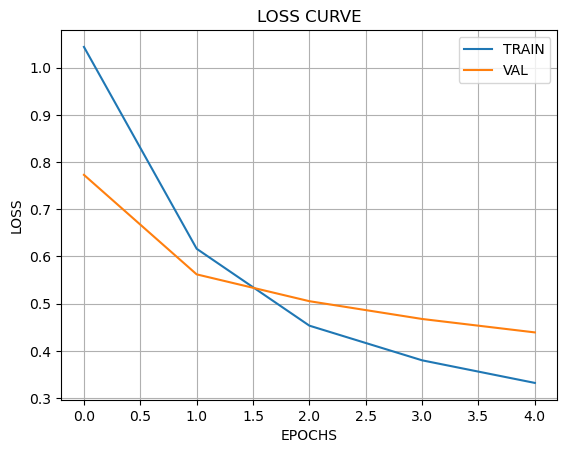

In [24]:
import matplotlib.pyplot as plt

train_loss = model.history.history['loss']
val_loss = model.history.history['val_loss']

plt.plot(train_loss)
plt.plot(val_loss) 
# plt.ylim((0,300))
plt.xlabel("EPOCHS")
plt.ylabel('LOSS')
plt.legend(["TRAIN", "VAL"])
plt.title("LOSS CURVE")
plt.grid()
plt.show()

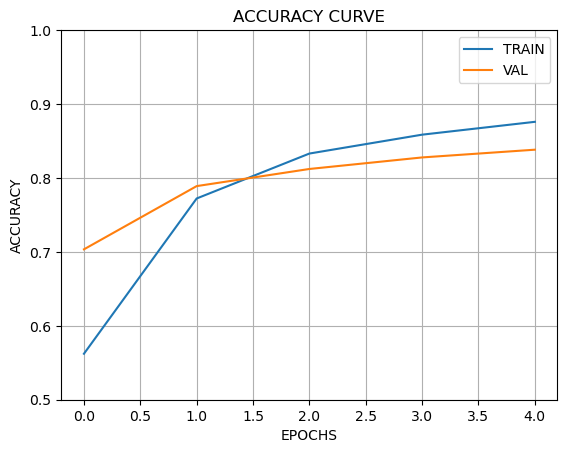

In [25]:
train_acc = model.history.history['accuracy']
val_acc = model.history.history['val_accuracy']

plt.plot(train_acc)
plt.plot(val_acc)
plt.ylim((0.5,1))
plt.xlabel("EPOCHS")
plt.ylabel('ACCURACY')
plt.legend(["TRAIN", "VAL"])
plt.title("ACCURACY CURVE")
plt.grid()
plt.show()

In [26]:
test_loss, test_acc = model.evaluate(X_val, y_val)
print(f"Test Accuracy: {test_acc}")

463/463 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.8363 - loss: 0.4462
Test Accuracy: 0.8382432460784912


In [ ]:
import pickle

# Save tokenizer
with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

# Also save model if you haven't
model.save('sentiment_model.h5')


In [ ]:
import numpy as np
from keras.preprocessing.sequence import pad_sequences

# Correct class names based on your array
class_names = ["Irrelevant", "Negative", "Neutral", "Positive"]

def predict_sentiment(text):
    # Step 1: Tokenize
    seq = tokenizer.texts_to_sequences([text])
    
    # Step 2: Pad
    padded = pad_sequences(seq, maxlen=110)
    
    # Step 3: Predict
    pred = model.predict(padded)
    
    # Step 4: Get the class with highest probability
    class_idx = np.argmax(pred, axis=1)[0]
    
    # Step 5: Map to label
    sentiment = class_names[class_idx]
    
    return sentiment

# Example usage
print(predict_sentiment("I love this app!"))
print(predict_sentiment("This is awful and useless."))
print(predict_sentiment("It’s okay, nothing special."))
print(predict_sentiment("What are you even talking about?"))


In [ ]:
model.save('sentiment_model.h5')
with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

In [ ]:
import tkinter as tk
from tkinter import messagebox
from keras.models import load_model
from keras.preprocessing.sequence import pad_sequences
import numpy as np
import pickle

# Load model and tokenizer
model = load_model('sentiment_model.h5')

with open('tokenizer.pkl', 'rb') as f:
    tokenizer = pickle.load(f)

# Class names as per your order
class_names = ["Irrelevant", "Negative", "Neutral", "Positive"]

# Function to predict sentiment (without saving the prediction)
def predict_sentiment():
    text = entry.get()
    if not text:
        messagebox.showwarning("Warning", "Please enter some text!")
        return
    
    # Convert the text to sequence of integers
    seq = tokenizer.texts_to_sequences([text])
    
    # Pad the sequence
    padded = pad_sequences(seq, maxlen=110)
    
    # Predict sentiment
    pred = model.predict(padded)
    class_idx = np.argmax(pred, axis=1)[0]
    sentiment = class_names[class_idx]
    
    # Display prediction
    result_label.config(text=f"Prediction: {sentiment}")

# Setup Tkinter window
root = tk.Tk()
root.title("Sentiment Predictor")

# Input label and entry box
tk.Label(root, text="Enter Text:", font=("Arial", 14)).pack(pady=10)
entry = tk.Entry(root, width=50, font=("Arial", 14))
entry.pack(pady=5)

# Predict button
tk.Button(root, text="Predict Sentiment", command=predict_sentiment, font=("Arial", 14)).pack(pady=10)

# Label to display prediction result
result_label = tk.Label(root, text="", font=("Arial", 16))
result_label.pack(pady=10)

# Run the Tkinter event loop
root.mainloop()
